# FairPrice — End-to-end walkthrough
This notebook runs every phase of the workflow step by step using the `fairprice` package.
The same functions power `run_pipeline.py` and the Streamlit app, so nothing here is copy-pasted logic.

| Phase | Module |
|---|---|
| 1 Ingestion & schema validation | `data_ingestion.py` |
| 2 Cleaning | `preprocessing.py` |
| 3 EDA | `eda.py` |
| 4 Feature engineering | `features.py` |
| 5-6 Training, tuning, K-fold CV | `train.py` |
| 7 Evaluation & SHAP | `evaluate.py`, `explain.py` |
| 8 Inference | `predict.py` |

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import pandas as pd
from IPython.display import Image, display
from fairprice import config
pd.set_option('display.width', 160)

## Phase 1 — Data ingestion & schema validation

In [2]:
from fairprice.data_ingestion import ingest

raw_df = ingest()
raw_df.head()

11:31:51 | fairprice.data_ingestion | Loading cached raw data from california_housing.csv


11:31:51 | fairprice.data_ingestion | Schema OK: 20640 rows x 9 columns


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [3]:
raw_df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.87,1.90,0.50,2.56,3.53,4.74,15.00
HouseAge,20640.0,28.64,12.59,1.00,18.00,29.00,37.00,52.00
AveRooms,20640.0,5.43,2.47,0.85,4.44,5.23,6.05,141.91
AveBedrms,20640.0,1.10,0.47,0.33,1.01,1.05,1.10,34.07
Population,20640.0,1425.48,1132.46,3.00,787.00,1166.00,1725.00,35682.00
AveOccup,20640.0,3.07,10.39,0.69,2.43,2.82,3.28,1243.33
Latitude,20640.0,35.63,2.14,32.54,33.93,34.26,37.71,41.95
Longitude,20640.0,-119.57,2.00,-124.35,-121.80,-118.49,-118.01,-114.31
MedHouseVal,20640.0,2.07,1.15,0.15,1.20,1.80,2.65,5.00


## Phase 2 — Cleaning
Row-level rules only (nothing learned from data → no leakage). Capped targets (`5.00001` = "$500k or more") are removed because their true value is unknown.

In [4]:
from fairprice.preprocessing import clean_data

clean_df, cleaning_report = clean_data(raw_df)
print(json.dumps(cleaning_report, indent=2))

11:31:51 | fairprice.preprocessing | Data quality before cleaning: {'rows': 20640, 'missing_values': {}, 'duplicate_rows': 0, 'out_of_range_rows': 0, 'capped_target_rows': 992}


11:31:51 | fairprice.preprocessing | Removed rows: {'missing_target': 0, 'duplicates': 0, 'out_of_range': 0, 'capped_target': 992} -> 19648 rows remain


{
  "before": {
    "rows": 20640,
    "missing_values": {},
    "duplicate_rows": 0,
    "out_of_range_rows": 0,
    "capped_target_rows": 992
  },
  "removed": {
    "missing_target": 0,
    "duplicates": 0,
    "out_of_range": 0,
    "capped_target": 992
  },
  "rows_after": 19648
}


## Phase 3 — Exploratory data analysis

In [5]:
from fairprice.eda import run_eda

eda_summary = run_eda(raw_df, clean_df)
pd.DataFrame({'skewness': eda_summary['skewness'],
              'corr_with_target_raw': eda_summary['target_correlation_raw']})

11:31:55 | fairprice.eda          | EDA figures saved to reports\figures


11:31:55 | fairprice.eda          | Highly correlated raw pairs: [{'feature_a': 'AveRooms', 'feature_b': 'AveBedrms', 'correlation': 0.848}, {'feature_a': 'Latitude', 'feature_b': 'Longitude', 'correlation': -0.925}]


,skewness,corr_with_target_raw
MedInc,1.65,0.688
HouseAge,0.06,0.106
AveRooms,20.70,0.152
AveBedrms,31.32,-0.047
Population,4.94,-0.025
AveOccup,97.64,-0.024
Latitude,0.47,-0.144
Longitude,-0.30,-0.046


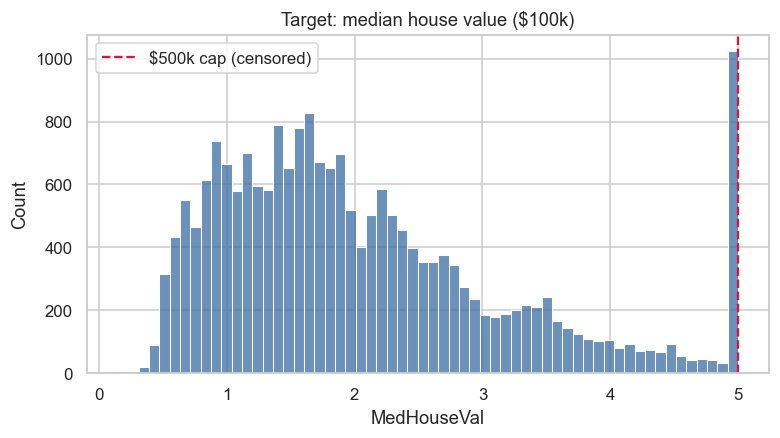

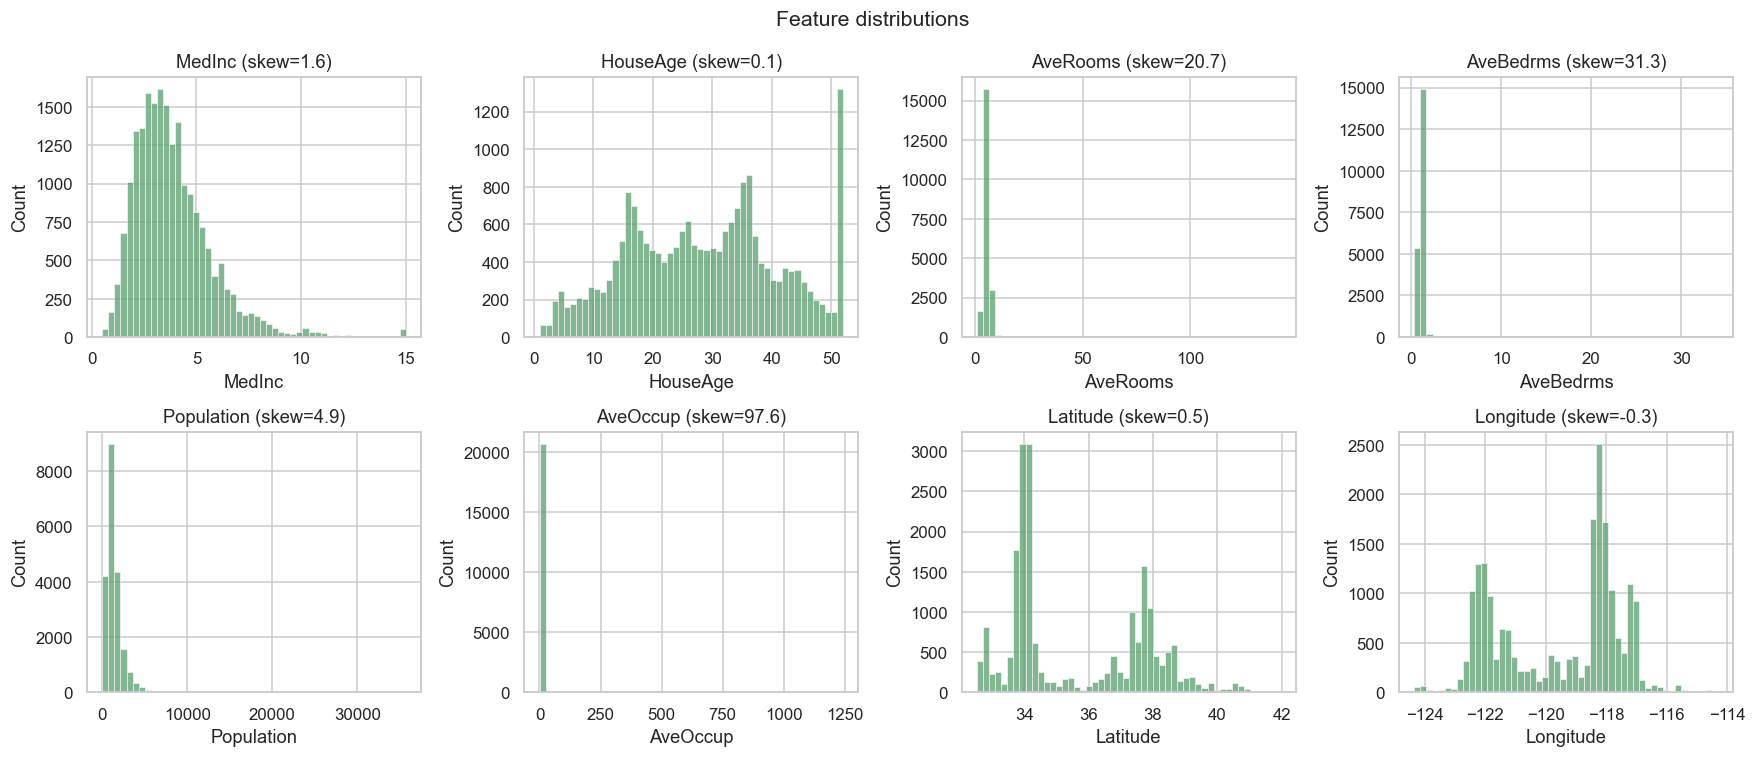

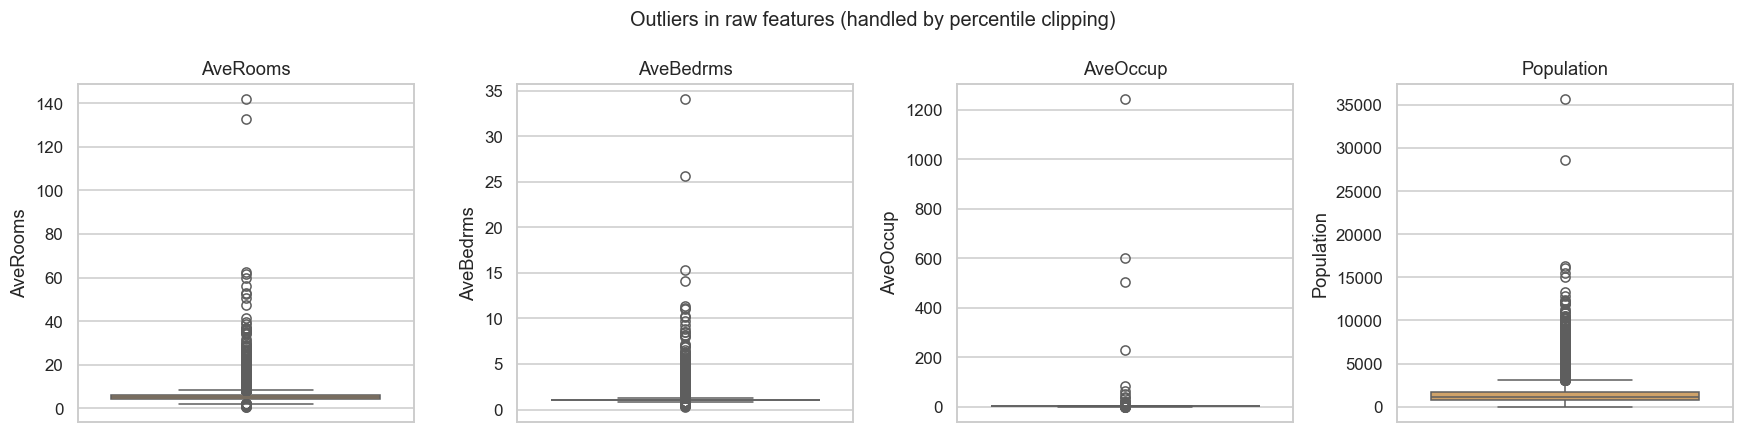

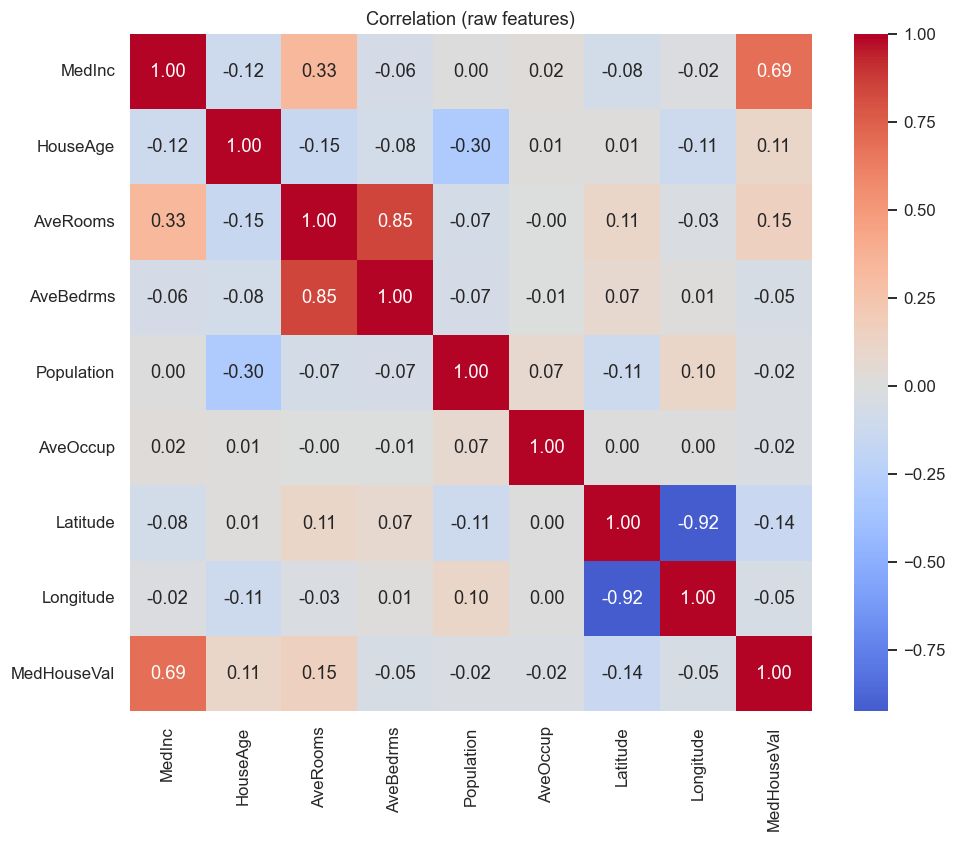

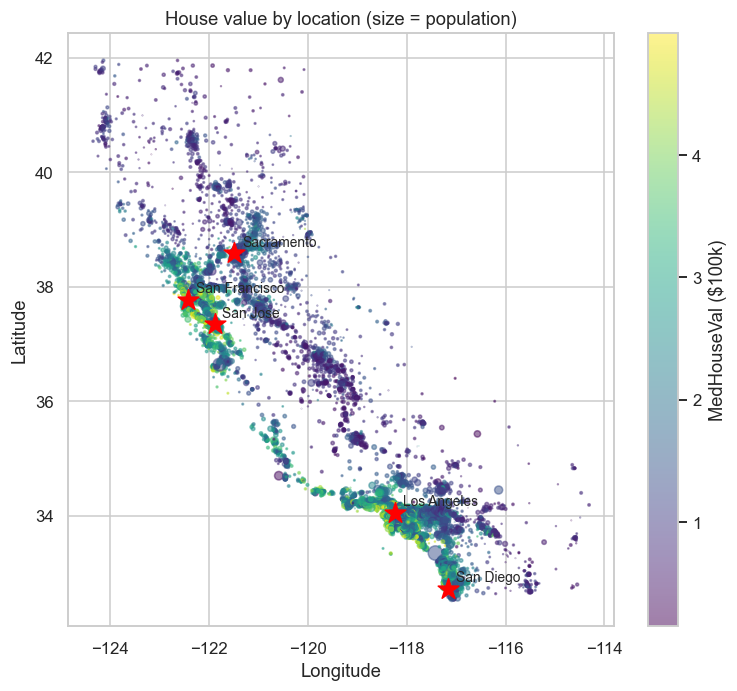

In [6]:
for name in ['01_target_distribution', '02_feature_distributions', '03_outliers_boxplot',
             '04_correlation_heatmap_raw', '05_geographic_value_map']:
    display(Image(filename=str(config.FIGURES_DIR / f'{name}.png')))

**Findings → decisions**
- Target spike at 5.0 → drop capped rows.
- `AveOccup`, `AveRooms`, `AveBedrms` are extremely skewed (outliers) → percentile clipping.
- `AveRooms` ↔ `AveBedrms` correlation 0.85 → replace `AveBedrms` with `BedroomRatio`.
- Prices cluster near the coast / big cities → `DistToCity` feature.
- `Latitude` ↔ `Longitude` (-0.92) is California's diagonal shape; both are needed for location, so both stay.

## Phase 4 — Feature engineering

In [7]:
from fairprice.features import FeatureEngineer, build_preprocessor

FeatureEngineer().transform(clean_df[config.FEATURES]).head()

,MedInc,HouseAge,AveRooms,Population,AveOccup,Latitude,Longitude,BedroomRatio,RoomsPerPerson,DistToCity
0,8.3252,41.0,6.984127,322.0,2.555556,37.88,-122.23,0.146591,2.732919,20.690495
1,8.3014,21.0,6.238137,2401.0,2.109842,37.86,-122.22,0.155797,2.956685,20.219026
2,7.2574,52.0,8.288136,496.0,2.802260,37.85,-122.24,0.129516,2.957661,18.143279
3,5.6431,52.0,5.817352,558.0,2.547945,37.85,-122.25,0.184458,2.283154,17.382961
4,3.8462,52.0,6.281853,565.0,2.181467,37.85,-122.25,0.172096,2.879646,17.382961


In [8]:
print('Highly correlated after clipping:', eda_summary['high_correlation_pairs_after_clipping'])
pd.DataFrame({'raw': eda_summary['target_correlation_raw'],
              'processed': eda_summary['target_correlation_processed']}).round(3)

Highly correlated after clipping: [{'feature_a': 'Latitude', 'feature_b': 'Longitude', 'correlation': -0.926}]


,raw,processed
MedInc,0.688,0.650
HouseAge,0.106,0.065
AveRooms,0.152,0.222
AveBedrms,-0.047,NaN
Population,-0.025,0.013
AveOccup,-0.024,-0.251
Latitude,-0.144,-0.148
Longitude,-0.046,-0.046
BedroomRatio,NaN,-0.238
RoomsPerPerson,NaN,0.313


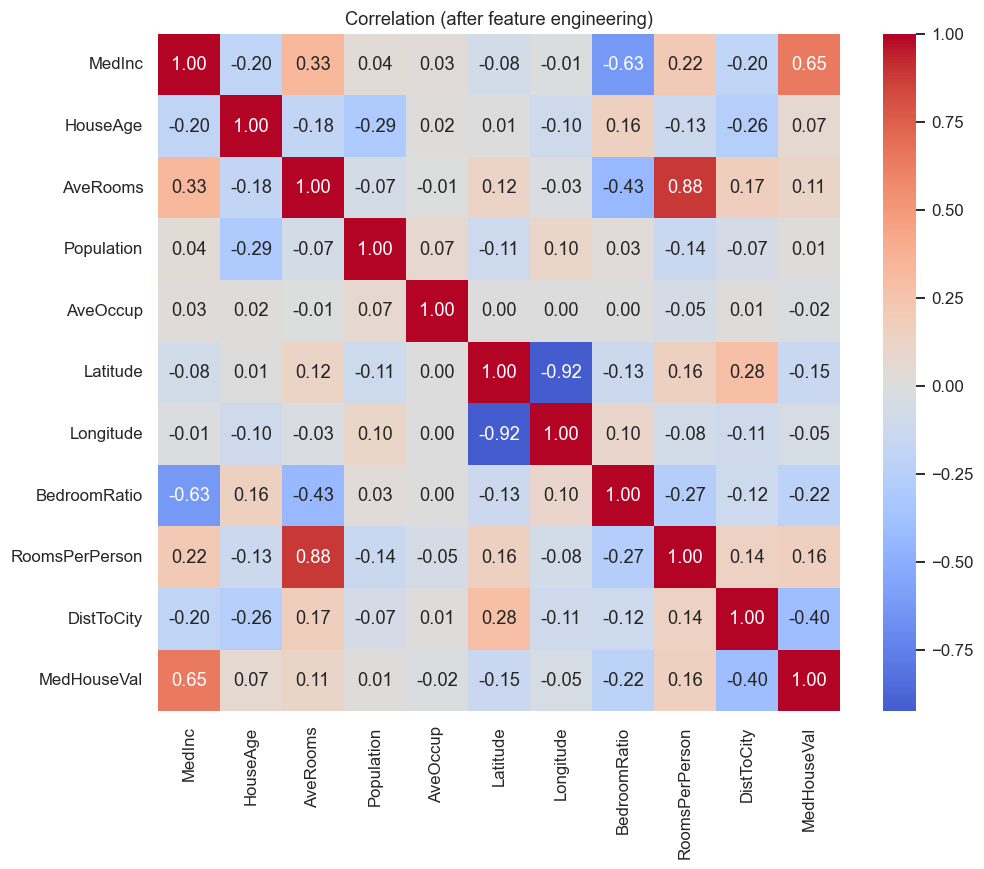

In [9]:
display(Image(filename=str(config.FIGURES_DIR / '06_correlation_heatmap_engineered.png')))

## Phases 5-6 — Split, train, tune, cross-validate
Stratified 80/20 split on income bands. Every model sits in the same Pipeline (features → impute → clip → scale → model). `fast=True` keeps this notebook quick; `run_pipeline.py` does the full search.

In [10]:
from fairprice.train import split_data, train_all

X_train, X_test, y_train, y_test = split_data(clean_df)
results = train_all(X_train, y_train, fast=True)

11:32:02 | fairprice.train        | Train: 15718 rows | Test: 3930 rows


11:32:02 | fairprice.train        | Training 5 models with 5-fold CV (search iterations: 4 conventional, 2 ANN)


11:32:02 | fairprice.train        | LinearRegression CV RMSE = 0.5738 +/- 0.0129  (0.2s)  {}


11:32:03 | fairprice.train        | Ridge            CV RMSE = 0.5738 +/- 0.0129  (0.6s)  {'alpha': np.float64(0.7459343285726545)}


11:32:19 | fairprice.train        | RandomForest     CV RMSE = 0.4476 +/- 0.0107  (16.6s)  {'n_estimators': 100, 'min_samples_leaf': 4, 'max_samples': None, 'max_features': 0.7, 'max_depth': 15}


11:32:39 | fairprice.train        | XGBoost          CV RMSE = 0.4068 +/- 0.0107  (19.7s)  {'subsample': 1.0, 'reg_lambda': 5, 'n_estimators': 800, 'min_child_weight': 5, 'max_depth': 6, 'learning_rate': 0.05, 'colsample_bytree': 0.85}


11:37:40 | fairprice.train        | ANN              CV RMSE = 0.4790 +/- 0.0099  (300.8s)  {'activation': 'relu', 'batch_size': 64, 'dropout': 0.2, 'hidden_layers': (128, 64, 32), 'kernel_initializer': 'glorot_uniform', 'l2': 0.0, 'learning_rate': np.float64(0.0011856906977823463), 'optimizer': 'sgd'}


## Phase 7 — Evaluation & model selection
The winner is picked on **CV RMSE**; the test set is only used to report the final score.

In [11]:
from fairprice.evaluate import build_leaderboard, select_best, regression_metrics

leaderboard = build_leaderboard(results, X_train, y_train, X_test, y_test)
leaderboard

11:37:41 | fairprice.evaluate     | Leaderboard (sorted by CV RMSE):
           model          family  cv_rmse_mean  cv_rmse_std  train_rmse  test_rmse  test_mae  test_r2  test_mae_dollars  overfit_gap  fit_seconds
         XGBoost Conventional ML        0.4068       0.0107      0.2333     0.3837    0.2590   0.8389             25897       0.1504         19.7
    RandomForest Conventional ML        0.4476       0.0107      0.2903     0.4225    0.2862   0.8047             28624       0.1322         16.6
             ANN  Neural Network        0.4790       0.0099      0.4771     0.4720    0.3343   0.7562             33426      -0.0051        300.8
           Ridge Conventional ML        0.5738       0.0129      0.5735     0.5571    0.4136   0.6605             41364      -0.0164          0.6
LinearRegression Conventional ML        0.5738       0.0129      0.5735     0.5571    0.4136   0.6604             41365      -0.0164          0.2


,model,family,cv_rmse_mean,cv_rmse_std,train_rmse,test_rmse,test_mae,test_r2,test_mae_dollars,overfit_gap,fit_seconds
0,XGBoost,Conventional ML,0.4068,0.0107,0.2333,0.3837,0.2590,0.8389,25897,0.1504,19.7
1,RandomForest,Conventional ML,0.4476,0.0107,0.2903,0.4225,0.2862,0.8047,28624,0.1322,16.6
2,ANN,Neural Network,0.4790,0.0099,0.4771,0.4720,0.3343,0.7562,33426,-0.0051,300.8
3,Ridge,Conventional ML,0.5738,0.0129,0.5735,0.5571,0.4136,0.6605,41364,-0.0164,0.6
4,LinearRegression,Conventional ML,0.5738,0.0129,0.5735,0.5571,0.4136,0.6604,41365,-0.0164,0.2


In [12]:
best = select_best(results, leaderboard)
print(best['name'], best['best_params'])
regression_metrics(y_test, best['pipeline'].predict(X_test))

11:37:41 | fairprice.evaluate     | Best model by CV RMSE: XGBoost


XGBoost {'subsample': 1.0, 'reg_lambda': 5, 'n_estimators': 800, 'min_child_weight': 5, 'max_depth': 6, 'learning_rate': 0.05, 'colsample_bytree': 0.85}


{'rmse': 0.3837053072934274,
 'mae': 0.2589690544369312,
 'r2': 0.8389234618568708}

### Saved diagnostics from the full pipeline run

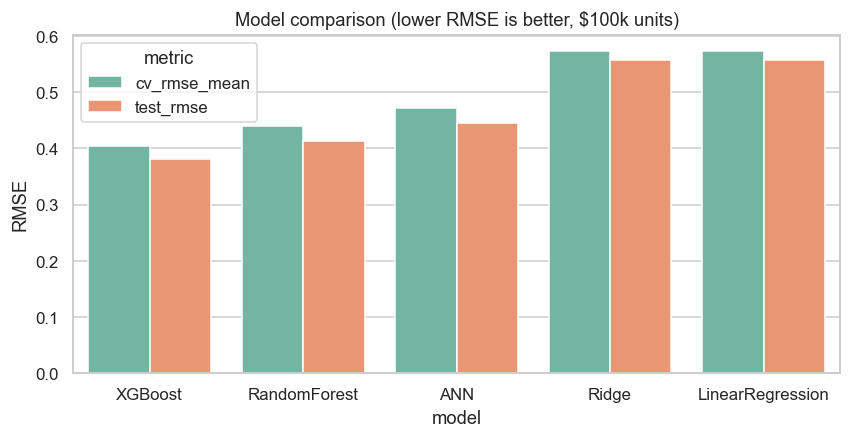

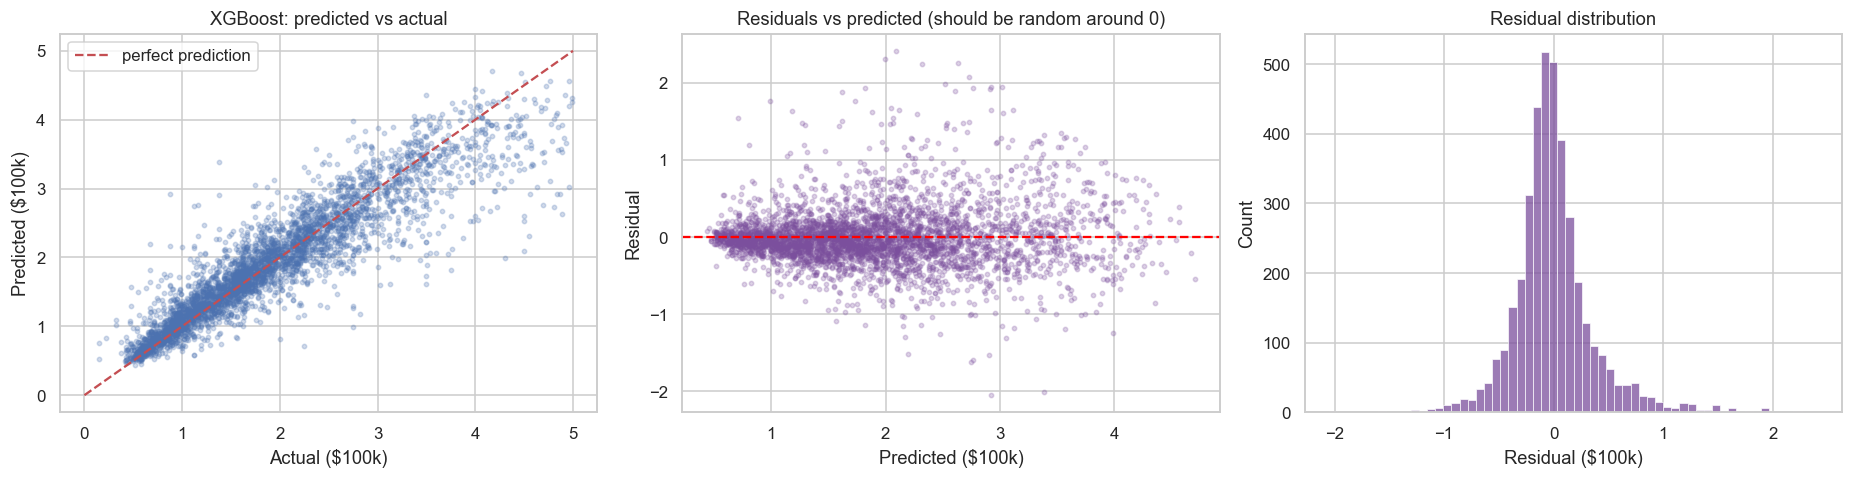

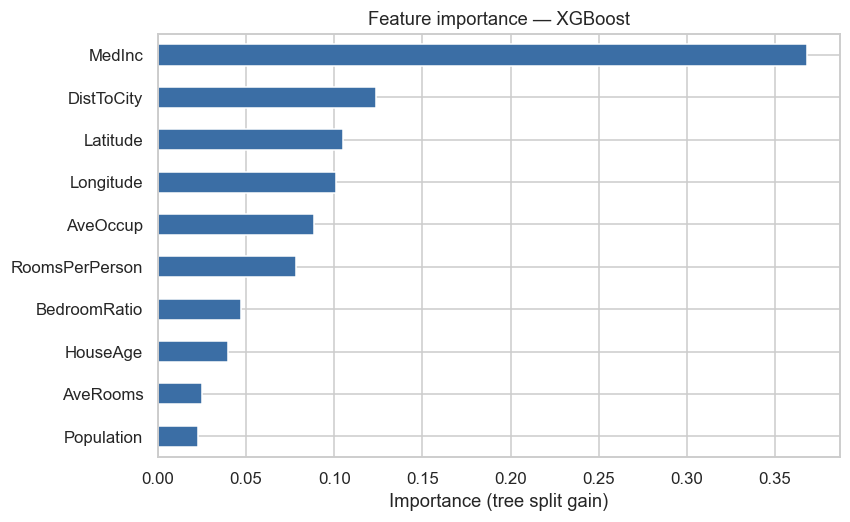

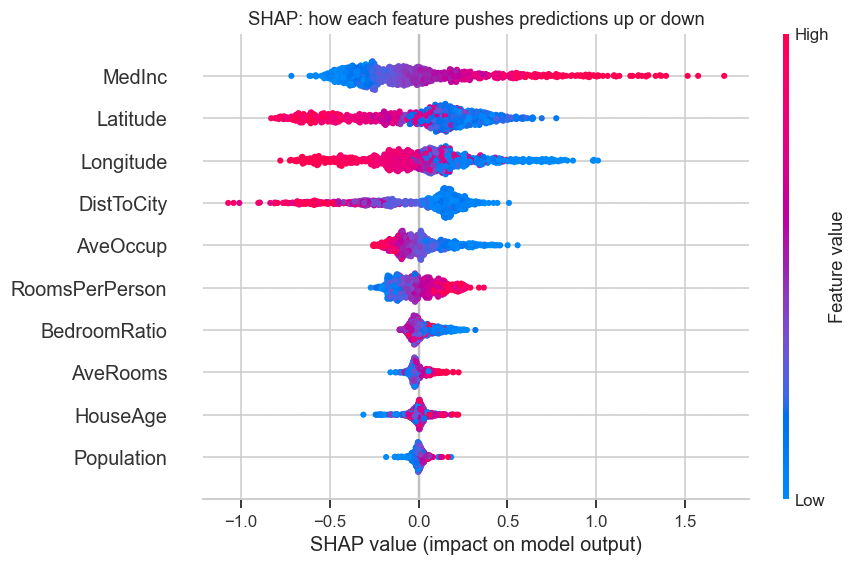

In [13]:
for name in ['07_model_comparison', '08_residual_analysis', '09_feature_importance', '10_shap_summary']:
    path = config.FIGURES_DIR / f'{name}.png'
    if path.exists():
        display(Image(filename=str(path)))

## Phase 8 — Inference with the saved model + Fair Price Check

In [14]:
from fairprice.predict import load_model, load_background, predict_value, validate_input, fair_price_verdict
from fairprice.explain import make_explainer, explain_prediction

pipeline, meta = load_model()
district = {'MedInc': 4.5, 'HouseAge': 25, 'AveRooms': 5.0, 'AveBedrms': 1.0,
            'Population': 1200, 'AveOccup': 3.0, 'Latitude': 34.05, 'Longitude': -118.24}
print('Validation:', validate_input(district, meta['feature_ranges']))
predicted = predict_value(pipeline, district)
print(f'Predicted: ${predicted:,.0f}')
fair_price_verdict(predicted, asking=300_000, tolerance=meta['test_mae_dollars'])

Validation: ([], [])
Predicted: $216,307


C:\Users\ck897\AppData\Roaming\Python\Python312\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'verdict': 'Overpriced',
 'difference_pct': 38.7,
 'fair_low': 190707,
 'fair_high': 241907}

In [15]:
explainer = make_explainer(pipeline, load_background())
base, table = explain_prediction(pipeline, explainer, pd.DataFrame([district]))
print(f'Base value: ${base:,.0f}')
table.round(2)

Base value: $192,455


,feature,value,contribution_dollars
0,Latitude,34.05,29268.119141
1,DistToCity,0.00,23180.000000
2,RoomsPerPerson,1.67,-12694.509766
3,Longitude,-118.24,-12309.059570
4,AveOccup,3.00,-10568.009766
5,MedInc,4.50,8421.419922
6,AveRooms,5.00,-5249.000000
7,BedroomRatio,0.20,1882.079956
8,HouseAge,25.00,1817.160034
9,Population,1200.00,104.080002


### Edge cases are rejected, not silently predicted

In [16]:
print(validate_input({**district, 'AveBedrms': 9}))
print(validate_input({**district, 'Latitude': 40.7, 'Longitude': -74.0}))
print(validate_input({**district, 'MedInc': 'abc'}))

(['Average bedrooms cannot be greater than average rooms.'], [])
(['Longitude=-74 is outside the valid range [-124.6, -114].'], [])
(["MedInc must be a number (got 'abc')."], [])
